# Inventory Versioning Demo — NSI sample

This notebook walks through the inventory versioning feature
([ADR-versioning](../docs/decisions/ADR-versioning.md)) on the 45,622-structure
NSI sample (`test/data/nsi.parquet`, mostly Rockwall County, TX):

1. **Release v1** — load the sample and commit it as version `nsi-sample-v1`.
2. **Release v2** — load a modified copy (demolitions, attribute corrections,
   re-geocoded points, new construction) as `nsi-sample-v2`.
3. **Time travel** — query either version with plain SQL (`VERSION AS OF`).
4. **Diff** — which buildings were added / removed / modified, and which columns.
5. **History** — who changed a building, when, and why.
6. **Project branches** — edit a branch without touching `main`, merge it back
   (fast-forward and three-way), and see a merge conflict get refused.
7. **Pinned exports** — export a version with a manifest that pins it, so the
   export is reproducible after the inventory moves on.
8. **Consistency check** — registry, tags, change log, and ADR invariants.

**How it works.** A *version* is an Apache Iceberg **tag** of the same name on
`rqm.inventory.buildings` and `rqm.inventory.geometries`, plus a row in
`rqm.inventory.inventory_versions` (editor, reason, source file, snapshot ids,
change counts) and per-building rows in `rqm.inventory.inventory_changes`.
Loads are full-replacement `MERGE` upserts, so a new version stores only what
changed. Project inventories are Iceberg **branches**. The catalog is Iceberg's
JDBC catalog on a SQLite file inside the warehouse (swap the URI for Postgres to
share it between editors).

The library is `tools/versioning.py`; the same operations are available from
the command line via `tools/ingest_nsi.py --version ...` and
`tools/rqm_version.py`.

## 0. Setup

In [1]:
import json
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import shapely

# Locate the repo root by walking up from the notebook's cwd.
REPO = Path.cwd().resolve()
while REPO != REPO.parent and not (REPO / "tools" / "versioning.py").exists():
    REPO = REPO.parent
assert (REPO / "tools" / "versioning.py").exists(), (
    f"repo root not found from {Path.cwd()}"
)
sys.path.insert(0, str(REPO / "tools"))

SAMPLE = REPO / "test" / "data" / "nsi.parquet"

# Scratch space on the Linux data volume (RQM_DATA_DIR, set by the
# devcontainer); falls back to test/ (gitignored). Recreated on every run so
# the demo always starts from an empty inventory.
DATA_DIR = Path("/workspaces/rqm-data-model/test")
SCRATCH = DATA_DIR / "versioning-notebook"
WAREHOUSE = SCRATCH / "warehouse"
INPUTS = SCRATCH / "inputs"
EXPORTS = SCRATCH / "exports"
if SCRATCH.exists():
    shutil.rmtree(SCRATCH)
for d in (WAREHOUSE, INPUTS, EXPORTS):
    d.mkdir(parents=True)

CATALOG = "rqm"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print(f"sample:    {SAMPLE}")
print(f"warehouse: {WAREHOUSE}")

sample:    /workspaces/rqm-data-model/test/data/nsi.parquet
warehouse: /workspaces/rqm-data-model/test/versioning-notebook/warehouse


### Boot Spark + Sedona + Iceberg

`SparkSettings` defaults to the JDBC catalog: Iceberg keeps each table's
current-metadata pointer in `<warehouse>/catalog.db` (SQLite) and commits with
a database transaction. Tables live in the `inventory` namespace. The sample is
small, so a few local tasks and 8 shuffle partitions are plenty.

In [3]:
import versioning as v
from ingest_nsi import (
    NAMESPACE,
    SparkSettings,
    apply_schema,
    build_spark,
    load_buildings,
    load_geometries,
    local_master,
    spark_conf,
    table_name,
)

DRIVER_MEMORY = "8g"
settings = SparkSettings(
    warehouse=WAREHOUSE,
    catalog=CATALOG,
    master=local_master(DRIVER_MEMORY),
    conf={
        "spark.driver.memory": DRIVER_MEMORY,
        "spark.sql.shuffle.partitions": "8",
        "spark.ui.showConsoleProgress": "false",
    },
)
spark = build_spark(settings)
spark.sparkContext.setLogLevel("ERROR")

for key, value in spark_conf(settings).items():
    if key.startswith(f"spark.sql.catalog.{CATALOG}"):
        print(f"{key} = {value}")

BUILDINGS = table_name(CATALOG, "buildings")  # rqm.inventory.buildings
GEOMETRIES = table_name(CATALOG, "geometries")  # rqm.inventory.geometries

apply_schema(spark, CATALOG)
spark.sql(f"SHOW TABLES IN {CATALOG}.{NAMESPACE}").toPandas()

spark.sql.catalog.rqm = org.apache.iceberg.spark.SparkCatalog
spark.sql.catalog.rqm.type = jdbc
spark.sql.catalog.rqm.warehouse = file:///workspaces/rqm-data-model/test/versioning-notebook/warehouse
spark.sql.catalog.rqm.uri = jdbc:sqlite:/workspaces/rqm-data-model/test/versioning-notebook/warehouse/catalog.db
spark.sql.catalog.rqm.jdbc.schema-version = V1


,namespace,tableName,isTemporary
0,inventory,buildings,False
1,inventory,geometries,False
2,inventory,inventory_changes,False
3,inventory,inventory_versions,False


In [4]:
from versioning import file_sha256


def load(parquet, version, *, editor, reason, branch="main", kind="release"):
    # Full-replacement MERGE of buildings, then geometries, then commit a version.
    load_buildings(spark, parquet, CATALOG, branch=branch)
    load_geometries(spark, parquet, CATALOG, branch=branch)
    return v.commit_version(
        spark,
        CATALOG,
        version,
        editor=editor,
        reason=reason,
        branch=branch,
        kind=kind,
        source_uri=str(parquet),
        source_sha256=file_sha256(parquet),
    )


def registry():
    cols = [
        "version_name",
        "parent_version",
        "merged_version",
        "branch",
        "kind",
        "editor",
        "reason",
        "n_buildings",
        "n_added",
        "n_removed",
        "n_changed",
    ]
    df = v.list_versions(spark, CATALOG).select(*cols).toPandas()
    return df.fillna({"parent_version": "—", "merged_version": "—"})


def sql(query):
    return spark.sql(query).toPandas()

## 1. Release v1 — the initial inventory

The first load of an empty inventory is a *root* version: no parent, every
building counts as added.

In [5]:
%%time
info = load(
    SAMPLE, "nsi-sample-v1", editor="analyst-a", reason="Initial load of the NSI sample"
)
pd.Series(info)

CPU times: user 96.5 ms, sys: 90.2 ms, total: 187 ms
Wall time: 11.3 s


version_name                                                  nsi-sample-v1
parent_version                                                         None
merged_version                                                         None
branch                                                                 main
kind                                                                release
source_uri                 /workspaces/rqm-data-model/test/data/nsi.parquet
source_sha256             0bfe6ca0491c609930351ac1c0088d961e264caf41f01f...
editor                                                            analyst-a
reason                                       Initial load of the NSI sample
buildings_snapshot_id                                   8609066532160914145
geometries_snapshot_id                                  5262188503681551758
n_buildings                                                           45622
n_added                                                               45622
n_removed   

The version name is now an Iceberg tag on both tables, pointing at the snapshot
the load produced:

In [6]:
sql(f"SELECT name, type, snapshot_id FROM {BUILDINGS}.refs ORDER BY type, name")

,name,type,snapshot_id
0,main,BRANCH,8609066532160914145
1,nsi-sample-v1,TAG,8609066532160914145


## 2. Release v2 — a modified dataset

`make_modified_nsi` writes a modified copy of the sample, the kind of file a
later NSI release or a field-survey cleanup produces:

- 40 structures **removed** (demolitions);
- 120 **attribute corrections**: `found_ht` + 1 ft, half of them also
  `val_struct` x 1.10;
- 30 points **moved** 25 m (re-geocoded);
- 15 structures **added** (new construction, new `fd_id`s).

In [7]:
V2 = INPUTS / "nsi_sample_v2.parquet"
edits = v.make_modified_nsi(SAMPLE, V2)
pd.Series(
    {
        "removed": len(edits.removed),
        "attribute edits": len(edits.attribute_edits),
        "moved": len(edits.moved),
        "added": len(edits.added),
    },
    name="structures",
)

removed             40
attribute edits    120
moved               30
added               15
Name: structures, dtype: int64

Loading it is the same call. The `MERGE` matches rows on `building_id`
(= NSI `fd_id`): changed rows are updated, new ones inserted, missing ones
deleted from the head, and **unchanged rows are not rewritten**. The parent
defaults to the nearest earlier version on the branch.

In [8]:
%%time
load(
    V2,
    "nsi-sample-v2",
    editor="analyst-b",
    reason="Field survey: FFE corrections, re-geocoded points, demolitions, new construction",
)
registry()

CPU times: user 231 ms, sys: 158 ms, total: 389 ms
Wall time: 11.5 s


,version_name,parent_version,merged_version,branch,kind,editor,reason,n_buildings,n_added,n_removed,n_changed
0,nsi-sample-v1,—,—,main,release,analyst-a,Initial load of the NSI sample,45622,45622,0,0
1,nsi-sample-v2,nsi-sample-v1,—,main,release,analyst-b,"Field survey: FFE corrections, re-geocoded poi...",45597,15,40,150


The tables use merge-on-read writes, so v2's snapshot of `buildings` adds only
the 165 rewritten or new rows, plus deletion vectors that mask the 190 replaced
or removed ones. v1's 45,622 rows stay where they are:

In [9]:
sql(f"""
SELECT s.committed_at, s.operation,
       s.summary['added-records']          AS added_records,
       s.summary['added-position-deletes'] AS masked_rows,
       s.summary['added-dvs']              AS deletion_vectors,
       s.summary['total-records']          AS total_records_in_files,
       r.name                              AS tag
FROM {BUILDINGS}.snapshots s
LEFT JOIN {BUILDINGS}.refs r ON r.snapshot_id = s.snapshot_id AND r.type = 'TAG'
ORDER BY s.committed_at
""")

,committed_at,operation,added_records,masked_rows,deletion_vectors,total_records_in_files,tag
0,2026-11-10 21:07:40.943,append,45622,NaN,NaN,45622,nsi-sample-v1
1,2026-11-10 21:08:28.310,overwrite,165,190,1,45787,nsi-sample-v2


## 3. Time travel

Every version stays queryable. In plain SQL, `VERSION AS OF '<version>'` reads
a table as of a tag; `versioning.read_version` does the same from Python.
Here is one query run against both versions:

In [10]:
def exposure(version):
    return sql(f"""
        SELECT st_damcat, COUNT(*) AS structures,
               ROUND(SUM(val_struct) / 1e6, 2) AS val_struct_musd,
               ROUND(AVG(found_ht), 3) AS mean_found_ht
        FROM {BUILDINGS} VERSION AS OF '{version}'
        GROUP BY st_damcat
    """).set_index("st_damcat")


pd.concat({"v1": exposure("nsi-sample-v1"), "v2": exposure("nsi-sample-v2")}, axis=1)

v1                                       v2                              
          structures val_struct_musd mean_found_ht structures val_struct_musd mean_found_ht
st_damcat                                                                                  
IND              178          377.11         0.251        177          368.40         0.251
COM             4323         4239.15         0.252       4315         4237.05         0.254
PUB              257         1404.43         0.252        257         1404.43         0.252
RES            40864        23487.51         1.098      40848        23481.14         1.100

## 4. Diff two versions

`diff_versions` compares two versions building by building: buildings
attributes plus `geom`, the building's selected computation geometry.
`ingested_at` is ignored.

In [11]:
diff = v.diff_versions(spark, CATALOG, "nsi-sample-v1", "nsi-sample-v2").cache()
summary = v.diff_summary(diff)
display(pd.Series(summary["by_kind"], name="buildings"))
pd.Series(summary["by_column"], name="buildings with this column changed")

added        15
removed      40
modified    150
Name: buildings, dtype: int64

found_ht      120
val_struct     60
geom           30
x              30
y              30
Name: buildings with this column changed, dtype: int64

In [12]:
diff.orderBy("change_kind", "building_id").limit(8).toPandas()

,building_id,change_kind,changed_columns
0,127643133,added,None
1,127643134,added,None
2,127643135,added,None
3,127643136,added,None
4,127643137,added,None
5,127643138,added,None
6,127643139,added,None
7,127643140,added,None


Before/after values for a few corrected buildings. `compare_buildings` reads
both versions side by side:

In [13]:
corrected = sorted(edits.attribute_edits)[:6]
v.compare_buildings(
    spark,
    CATALOG,
    "nsi-sample-v1",
    "nsi-sample-v2",
    corrected,
    ["occtype", "found_ht", "val_struct"],
).toPandas()

,building_id,occtype_old,occtype_new,found_ht_old,found_ht_new,val_struct_old,val_struct_new
0,127598176,RES1-1SNB,RES1-1SNB,0.75,1.75,355924.540706,391516.990000
1,127598313,RES1-2SNB,RES1-2SNB,0.75,1.75,503460.641671,503460.641671
2,127599200,COM1,COM1,0.25,1.25,209786.337864,230764.970000
3,127599461,AGR1,AGR1,0.25,1.25,360650.166802,396715.180000
4,127599610,RES1-1SNB,RES1-1SNB,0.75,1.75,331381.116137,331381.116137
5,127599620,RES1-2SNB,RES1-2SNB,0.75,1.75,407461.005127,448207.110000


### Where the changes are

`geometries` is versioned with `buildings`, so v1 and v2 points come from the
same tags. Left: every structure, with v2's additions, removals, and moves.
Right: zoom on one re-geocoded building and its v1 → v2 move.

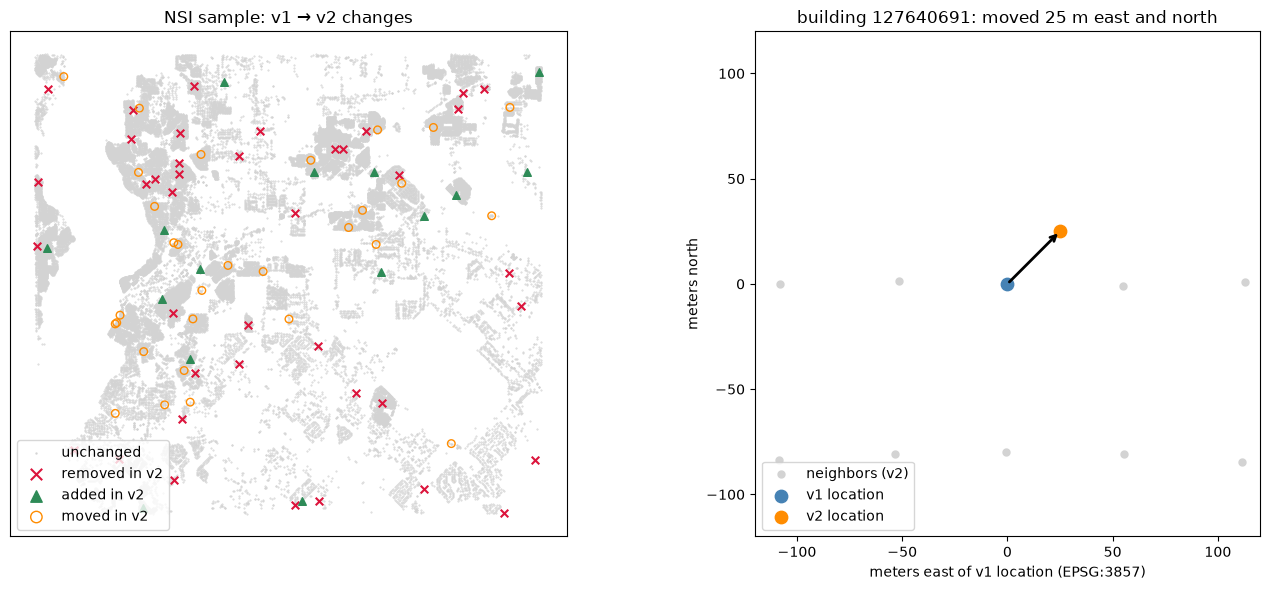

In [14]:
def points(version):
    df = sql(f"""
        SELECT building_id, spark_st_asbinary(geom) AS wkb
        FROM {GEOMETRIES} VERSION AS OF '{version}'
        WHERE purpose = 'computation' AND is_selected_for_export
    """)
    pts = shapely.from_wkb(df.pop("wkb").map(bytes))
    df["x"], df["y"] = shapely.get_x(pts), shapely.get_y(pts)
    return df.set_index("building_id")


p1, p2 = points("nsi-sample-v1"), points("nsi-sample-v2")
moved, added, removed = list(edits.moved), list(edits.added), list(edits.removed)

fig, (ax, zoom) = plt.subplots(1, 2, figsize=(14, 6))
ax.scatter(p2.x, p2.y, s=0.2, c="lightgray", label="unchanged")
ax.scatter(
    p1.loc[removed].x,
    p1.loc[removed].y,
    s=30,
    marker="x",
    c="crimson",
    label="removed in v2",
)
ax.scatter(
    p2.loc[added].x,
    p2.loc[added].y,
    s=30,
    marker="^",
    c="seagreen",
    label="added in v2",
)
ax.scatter(
    p2.loc[moved].x,
    p2.loc[moved].y,
    s=30,
    marker="o",
    facecolors="none",
    edgecolors="darkorange",
    label="moved in v2",
)
ax.set_title("NSI sample: v1 → v2 changes")
ax.legend(loc="lower left", markerscale=1.5)
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])

focus = moved[0]
x1, y1 = p1.loc[focus]
x2, y2 = p2.loc[focus]
r = 120  # meters around the v1 location
near = p2[(p2.x.between(x1 - r, x1 + r)) & (p2.y.between(y1 - r, y1 + r))]
zoom.scatter(near.x - x1, near.y - y1, s=25, c="lightgray", label="neighbors (v2)")
zoom.scatter([0], [0], s=80, c="steelblue", label="v1 location")
zoom.scatter([x2 - x1], [y2 - y1], s=80, c="darkorange", label="v2 location")
zoom.annotate(
    "", xy=(x2 - x1, y2 - y1), xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2)
)
zoom.set_xlim(-r, r)
zoom.set_ylim(-r, r)
zoom.set_xlabel("meters east of v1 location (EPSG:3857)")
zoom.set_ylabel("meters north")
zoom.set_aspect("equal")
zoom.set_title(f"building {focus}: moved {edits.move_m:.0f} m east and north")
zoom.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 5. Building history (who, when, why)

Each non-root version stores its per-building changes in `inventory_changes`,
attributed through the registry. `building_history` combines them with root
versions:

In [15]:
for label, building in [
    ("moved", edits.moved[0]),
    ("removed", edits.removed[0]),
    ("added", edits.added[0]),
]:
    print(f"{label} building {building}")
    display(v.building_history(spark, CATALOG, building).toPandas())

moved building 127640691


,version_name,branch,kind,editor,reason,created_at,change_kind,changed_columns
0,nsi-sample-v1,main,release,analyst-a,Initial load of the NSI sample,2026-11-10 21:07:45.921822,added,None
1,nsi-sample-v2,main,release,analyst-b,"Field survey: FFE corrections, re-geocoded poi...",2026-11-10 21:08:36.922250,modified,"[x, y, geom]"


removed building 127599015


,version_name,branch,kind,editor,reason,created_at,change_kind,changed_columns
0,nsi-sample-v1,main,release,analyst-a,Initial load of the NSI sample,2026-11-10 21:07:45.921822,added,None
1,nsi-sample-v2,main,release,analyst-b,"Field survey: FFE corrections, re-geocoded poi...",2026-11-10 21:08:36.922250,removed,None


added building 127643133


,version_name,branch,kind,editor,reason,created_at,change_kind,changed_columns
0,nsi-sample-v2,main,release,analyst-b,"Field survey: FFE corrections, re-geocoded poi...",2026-11-10 21:08:36.922250,added,None


## 6. Project branches

### 6.1 A calibration branch, merged by fast-forward

An analyst calibrates first-floor heights for residential structures in the
SFHA (FIRM zones A / AE) from elevation certificates. The work happens on a
branch, so `main`, and anyone running analyses on it, is unaffected until
the branch is merged.

In [16]:
v.create_branch(spark, CATALOG, "calibration", "nsi-sample-v2")
CAL_BUILDINGS = table_name(CATALOG, "buildings", branch="calibration")
print(CAL_BUILDINGS)

spark.sql(f"""
    UPDATE {CAL_BUILDINGS}
    SET found_ht = found_ht + 1.0, ingested_at = current_timestamp()
    WHERE firmzone IN ('A', 'AE') AND st_damcat = 'RES'
""")

sfha = "firmzone IN ('A', 'AE') AND st_damcat = 'RES'"
sql(f"""
    SELECT 'main' AS ref, COUNT(*) AS sfha_res, ROUND(AVG(found_ht), 3) AS mean_found_ht
    FROM {BUILDINGS} WHERE {sfha}
    UNION ALL
    SELECT 'calibration', COUNT(*), ROUND(AVG(found_ht), 3)
    FROM {CAL_BUILDINGS} WHERE {sfha}
""")

rqm.inventory.buildings.`branch_calibration`


,ref,sfha_res,mean_found_ht
0,main,381,1.228
1,calibration,381,2.228


Edits on a branch become a version when they are committed. The parent is
found from the branch's history (`nsi-sample-v2`):

In [17]:
info = v.commit_version(
    spark,
    CATALOG,
    "calibration-1",
    branch="calibration",
    kind="edit",
    editor="analyst-c",
    reason="FFE calibration from elevation certificates",
)
display(pd.Series(info)[["version_name", "parent_version", "branch", "n_changed"]])
v.list_branches(spark, CATALOG).toPandas()

version_name      calibration-1
parent_version    nsi-sample-v2
branch              calibration
n_changed                   381
dtype: object

,branch,buildings_snapshot_id,head_version
0,main,4741075110657942205,nsi-sample-v2
1,calibration,8978438493243715058,calibration-1


`main` has not moved since the branch was created, so the merge is a
fast-forward. Both tables' `main` refs move to the branch's snapshots and no
data is rewritten. The merge is recorded as its own version on `main`.

In [18]:
merged = v.merge_branch(
    spark,
    CATALOG,
    "calibration",
    version="nsi-sample-v3",
    editor="lead-reviewer",
    reason="Accept FFE calibration",
)
print("mode:", merged["mode"])
registry()

mode: fast-forward


,version_name,parent_version,merged_version,branch,kind,editor,reason,n_buildings,n_added,n_removed,n_changed
0,nsi-sample-v1,—,—,main,release,analyst-a,Initial load of the NSI sample,45622,45622,0,0
1,nsi-sample-v2,nsi-sample-v1,—,main,release,analyst-b,"Field survey: FFE corrections, re-geocoded poi...",45597,15,40,150
2,calibration-1,nsi-sample-v2,—,calibration,edit,analyst-c,FFE calibration from elevation certificates,45597,0,0,381
3,nsi-sample-v3,nsi-sample-v2,calibration-1,main,merge,lead-reviewer,Accept FFE calibration,45597,0,0,381


### 6.2 Parallel work, merged three-way

Two people now work at the same time. A buyout scenario removes five SFHA homes
on a `buyout-scenario` branch, while `main` gets a commercial revaluation. The
two change sets touch different buildings, so the merge replays the branch's
changes onto `main`.

In [19]:
v.create_branch(spark, CATALOG, "buyout-scenario", "nsi-sample-v3")
buyout_ids = [
    r.building_id
    for r in spark.sql(f"""
    SELECT building_id FROM {BUILDINGS}
    WHERE firmzone = 'AE' AND st_damcat = 'RES' ORDER BY building_id LIMIT 5
""").collect()
]
ids = ", ".join(map(str, buyout_ids))
for table in ("buildings", "geometries"):
    spark.sql(
        f"DELETE FROM {table_name(CATALOG, table, branch='buyout-scenario')} "
        f"WHERE building_id IN ({ids})"
    )
v.commit_version(
    spark,
    CATALOG,
    "buyout-1",
    branch="buyout-scenario",
    kind="edit",
    editor="planner",
    reason="Acquisition/demolition scenario",
)

# Meanwhile on main: +3% structure value for commercial buildings.
spark.sql(f"""
    UPDATE {BUILDINGS}
    SET val_struct = ROUND(val_struct * 1.03, 2), ingested_at = current_timestamp()
    WHERE st_damcat = 'COM'
""")
v.commit_version(
    spark,
    CATALOG,
    "nsi-sample-v4",
    kind="edit",
    editor="valuation-team",
    reason="2026 commercial revaluation",
)

merged = v.merge_branch(
    spark,
    CATALOG,
    "buyout-scenario",
    version="nsi-sample-v5",
    editor="lead-reviewer",
    reason="Adopt buyout scenario",
)
print("mode:", merged["mode"])
registry().tail(3)

mode: three-way


,version_name,parent_version,merged_version,branch,kind,editor,reason,n_buildings,n_added,n_removed,n_changed
4,buyout-1,nsi-sample-v3,—,buyout-scenario,edit,planner,Acquisition/demolition scenario,45592,0,5,0
5,nsi-sample-v4,nsi-sample-v3,—,main,edit,valuation-team,2026 commercial revaluation,45597,0,0,4315
6,nsi-sample-v5,nsi-sample-v4,buyout-1,main,merge,lead-reviewer,Adopt buyout scenario,45592,0,5,0


### 6.3 A conflict is refused

If both sides change the **same building** after they diverge, and end up
with different values, the merge refuses and writes nothing. It reports what
each side changed, so the editors can resolve it.

In [20]:
target = (
    spark.sql(f"""
    SELECT building_id FROM {BUILDINGS} WHERE st_damcat = 'COM' ORDER BY building_id LIMIT 1
""")
    .first()
    .building_id
)

v.create_branch(spark, CATALOG, "review-x", "nsi-sample-v5")
spark.sql(
    f"UPDATE {table_name(CATALOG, 'buildings', branch='review-x')} "
    f"SET found_ht = 3.0 WHERE building_id = {target}"
)
v.commit_version(
    spark,
    CATALOG,
    "review-x-1",
    branch="review-x",
    kind="edit",
    editor="reviewer-x",
    reason="Site visit: raised floor",
)

spark.sql(f"UPDATE {BUILDINGS} SET val_struct = 250000.0 WHERE building_id = {target}")
v.commit_version(
    spark,
    CATALOG,
    "nsi-sample-v6",
    kind="edit",
    editor="valuation-team",
    reason="Appraisal for one building",
)

try:
    v.merge_branch(
        spark, CATALOG, "review-x", version="nsi-sample-v7", editor="lead-reviewer"
    )
except v.MergeConflictError as err:
    print(err)
    display(pd.DataFrame([r.asDict() for r in err.conflicts]))

cannot merge 'review-x' into 'main': 1 building(s) changed on both since they diverged: 120469920


,building_id,source_change,source_columns,target_change,target_columns
0,120469920,modified,[found_ht],modified,[val_struct]


To resolve it, re-apply the reviewer's edit on top of the current `main`
version: branch from `nsi-sample-v6` and redo the edit. That branch merges by
fast-forward. The conflicting branch is dropped, but its committed version
`review-x-1` stays readable through its tag.

In [21]:
v.create_branch(spark, CATALOG, "review-x-rebased", "nsi-sample-v6")
spark.sql(
    f"UPDATE {table_name(CATALOG, 'buildings', branch='review-x-rebased')} "
    f"SET found_ht = 3.0 WHERE building_id = {target}"
)
v.commit_version(
    spark,
    CATALOG,
    "review-x-2",
    branch="review-x-rebased",
    kind="edit",
    editor="reviewer-x",
    reason="Site visit: raised floor (rebased on v6)",
)
merged = v.merge_branch(
    spark,
    CATALOG,
    "review-x-rebased",
    version="nsi-sample-v7",
    editor="lead-reviewer",
    reason="Accept site visit",
)
print("mode:", merged["mode"])
for branch in ("calibration", "buyout-scenario", "review-x", "review-x-rebased"):
    v.drop_branch(spark, CATALOG, branch)

display(
    v.compare_buildings(
        spark,
        CATALOG,
        "nsi-sample-v5",
        "nsi-sample-v7",
        [target],
        ["found_ht", "val_struct"],
    ).toPandas()
)
v.building_history(spark, CATALOG, target).toPandas()

mode: fast-forward


,building_id,found_ht_old,found_ht_new,val_struct_old,val_struct_new
0,120469920,0.25,3.0,1917595.5,250000.0


,version_name,branch,kind,editor,reason,created_at,change_kind,changed_columns
0,nsi-sample-v1,main,release,analyst-a,Initial load of the NSI sample,2026-11-10 21:07:45.921822,added,None
1,nsi-sample-v4,main,edit,valuation-team,2026 commercial revaluation,2026-11-10 21:10:51.832429,modified,[val_struct]
2,review-x-1,review-x,edit,reviewer-x,Site visit: raised floor,2026-11-10 21:11:24.640695,modified,[found_ht]
3,nsi-sample-v6,main,edit,valuation-team,Appraisal for one building,2026-11-10 21:11:28.156486,modified,[val_struct]
4,review-x-2,review-x-rebased,edit,reviewer-x,Site visit: raised floor (rebased on v6),2026-11-10 21:11:47.694567,modified,[found_ht]
5,nsi-sample-v7,main,merge,lead-reviewer,Accept site visit,2026-11-10 21:11:51.412174,modified,[found_ht]


The full lineage. Each version names its parent and, for merges, the branch
version it brought in:

In [22]:
registry()

,version_name,parent_version,merged_version,branch,kind,editor,reason,n_buildings,n_added,n_removed,n_changed
0,nsi-sample-v1,—,—,main,release,analyst-a,Initial load of the NSI sample,45622,45622,0,0
1,nsi-sample-v2,nsi-sample-v1,—,main,release,analyst-b,"Field survey: FFE corrections, re-geocoded poi...",45597,15,40,150
2,calibration-1,nsi-sample-v2,—,calibration,edit,analyst-c,FFE calibration from elevation certificates,45597,0,0,381
3,nsi-sample-v3,nsi-sample-v2,calibration-1,main,merge,lead-reviewer,Accept FFE calibration,45597,0,0,381
4,buyout-1,nsi-sample-v3,—,buyout-scenario,edit,planner,Acquisition/demolition scenario,45592,0,5,0
5,nsi-sample-v4,nsi-sample-v3,—,main,edit,valuation-team,2026 commercial revaluation,45597,0,0,4315
6,nsi-sample-v5,nsi-sample-v4,buyout-1,main,merge,lead-reviewer,Adopt buyout scenario,45592,0,5,0
7,review-x-1,nsi-sample-v5,—,review-x,edit,reviewer-x,Site visit: raised floor,45592,0,0,1
8,nsi-sample-v6,nsi-sample-v5,—,main,edit,valuation-team,Appraisal for one building,45592,0,0,1
9,review-x-2,nsi-sample-v6,—,review-x-rebased,edit,reviewer-x,Site visit: raised floor (rebased on v6),45592,0,0,1


## 7. Pinned exports

`export_version` reads a version at its recorded snapshots and writes one
parquet file plus `_rqm_version.json`, a manifest naming the version, its
snapshot ids, and its provenance. Parquet readers skip `_`-prefixed files.
Here are the SFHA structures as of v1 and as of the current head (v7):

In [23]:
SFHA = "firmzone IN ('A', 'AE')"
m1 = v.export_version(spark, CATALOG, "nsi-sample-v1", EXPORTS / "sfha_v1", where=SFHA)
m7 = v.export_version(spark, CATALOG, "nsi-sample-v7", EXPORTS / "sfha_v7", where=SFHA)
print(json.dumps(m7, indent=2))

{
  "version": "nsi-sample-v7",
  "catalog": "rqm",
  "namespace": "inventory",
  "snapshots": {
    "buildings": 1112726783409876718,
    "geometries": 7084819443171133685
  },
  "branch": "main",
  "kind": "merge",
  "parent_version": "nsi-sample-v6",
  "editor": "lead-reviewer",
  "reason": "Accept site visit",
  "version_created_at": "2026-11-10T21:11:51.412174",
  "source_uri": null,
  "source_sha256": null,
  "exported_at": "2026-11-10T21:12:04.324685+00:00",
  "row_count": 503,
  "filter": "firmzone IN ('A', 'AE')"
}


In [24]:
def summarize(path):
    df = pd.read_parquet(path)
    return pd.Series(
        {
            "structures": len(df),
            "mean_found_ht": round(df.found_ht.mean(), 3),
            "val_struct_musd": round(df.val_struct.sum() / 1e6, 3),
        }
    )


pd.DataFrame(
    {
        "v1 export": summarize(EXPORTS / "sfha_v1"),
        "v7 export": summarize(EXPORTS / "sfha_v7"),
    }
)

,v1 export,v7 export
structures,508.000,503.000
mean_found_ht,0.984,1.726
val_struct_musd,265.459,263.192


**Reproducibility.** The v1 export was written after the inventory had moved
on to v7, and it still holds exactly v1's data. Re-exporting from
the manifest gives an identical file:

In [25]:
manifest = v.read_export_manifest(EXPORTS / "sfha_v1")
again = v.export_version(
    spark,
    CATALOG,
    manifest["version"],
    EXPORTS / "sfha_v1_again",
    where=manifest["filter"],
)
a = pd.read_parquet(EXPORTS / "sfha_v1")
b = pd.read_parquet(EXPORTS / "sfha_v1_again")
print("same snapshots:", again["snapshots"] == manifest["snapshots"])
print("identical data:", a.equals(b))

same snapshots: True
identical data: True


## 8. Consistency check

`check_consistency` verifies the versioning invariants:

- every registered version is tagged on both tables at the recorded snapshots;
- no tag lacks a registry row (that would be a failed commit);
- parent chains resolve;
- the change log matches the registry counts;
- ADR-nsi-minimal rules 1, 2, and 7 hold **at every version**.

In [26]:
%%time
problems = v.check_consistency(spark, CATALOG)
print(problems or "OK: all versions consistent")

OK: all versions consistent
CPU times: user 28.9 ms, sys: 16.2 ms, total: 45.1 ms
Wall time: 8.6 s


### Under the hood

Everything above is ordinary Iceberg metadata, so any Iceberg-aware engine can
read a version by tag:

In [27]:
sql(f"""
    SELECT r.name AS ref, r.type, r.snapshot_id, s.committed_at, s.operation
    FROM {BUILDINGS}.refs r JOIN {BUILDINGS}.snapshots s USING (snapshot_id)
    ORDER BY s.committed_at, r.name
""")

,ref,type,snapshot_id,committed_at,operation
0,nsi-sample-v1,TAG,8609066532160914145,2026-11-10 21:07:40.943,append
1,nsi-sample-v2,TAG,4741075110657942205,2026-11-10 21:08:28.310,overwrite
2,calibration-1,TAG,8978438493243715058,2026-11-10 21:10:05.096,overwrite
3,nsi-sample-v3,TAG,8978438493243715058,2026-11-10 21:10:05.096,overwrite
4,buyout-1,TAG,8016753461981672153,2026-11-10 21:10:41.765,delete
5,nsi-sample-v4,TAG,466062649481035427,2026-11-10 21:10:47.576,overwrite
6,nsi-sample-v5,TAG,8476258392704963147,2026-11-10 21:11:04.705,delete
7,review-x-1,TAG,138359612031782978,2026-11-10 21:11:21.988,overwrite
8,nsi-sample-v6,TAG,8173347165266040123,2026-11-10 21:11:25.503,overwrite
9,main,BRANCH,1112726783409876718,2026-11-10 21:11:44.377,overwrite


In [28]:
sql(f"""
    SELECT version_name, change_kind, COUNT(*) AS buildings
    FROM {CATALOG}.{NAMESPACE}.inventory_changes
    GROUP BY version_name, change_kind
    ORDER BY version_name, change_kind
""")

,version_name,change_kind,buildings
0,buyout-1,removed,5
1,calibration-1,modified,381
2,nsi-sample-v2,added,15
3,nsi-sample-v2,modified,150
4,nsi-sample-v2,removed,40
5,nsi-sample-v3,modified,381
6,nsi-sample-v4,modified,4315
7,nsi-sample-v5,removed,5
8,nsi-sample-v6,modified,1
9,nsi-sample-v7,modified,1


## 9. Teardown

In [29]:
spark.stop()